# A 50/50 country, seen from outside

**Part B of 3.** Part A (`01_forecast.ipynb`) put a number on who wins. This part asks what a near-even split *is*, and what it does to the people inside it.

**A note on the point of view.** I am not Brazilian. I don't vote, and I have no side. From where I sit, an election is a ritual that turns about 120 million individual preferences into a single bit. The interesting question is what that ritual does to the 120 million.

This part is descriptive, not prescriptive. It is not an endorsement of anyone.

**Rules of evidence:**
- A number computed here comes from public data at a pinned version.
- A number cited from the literature carries its sample size, its year and a confidence label (`data/partb/literature.csv`).
- Where the evidence is thin or contested, the notebook says so instead of smoothing it over.

In [1]:
import sys, json, math
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
import forecast as F
matplotlib.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
STATS = {}   # every number the essay quotes is collected here and written to results/part_b_stats.json
frozen = json.loads((ROOT / "prereg" / "forecast_frozen.json").read_text())
pol = pd.read_csv(ROOT / "data/derived/vdem_polarization_1990_2025.csv")
pres = pd.read_csv(ROOT / "data/derived/vdem_presidential_margins_1990_2025.csv")
lit = pd.read_csv(ROOT / "data/partb/literature.csv")
close = pd.read_csv(ROOT / "data/partb/close_elections_sample.csv")
xt = pd.read_csv(F.RAW / "crosstabs_datafolha_2026.csv")

## 1. The arithmetic of a coin-flip electorate

Two quantities that are easy to confuse:

- **How uncertain the *outcome* is.** The frozen forecast gives Flávio a 0.85 chance. The binary entropy of that forecast is below 1 bit: we are fairly sure who wins.
- **How divided the *electorate* is.** At a median of 51.6 to 48.4, the entropy of the split is almost exactly 1 bit, the maximum possible. Pick a random voter and you know almost nothing about their ballot.

The election compresses a nearly maximal-entropy population into one fairly predictable bit. The headline below is what gets thrown away: how many people end up on the losing side. It is computed from the frozen forecast's own predictive draws, which are regenerated and checked against the frozen number.

In [2]:
row, v = F.run_arm(F.ArmConfig("M2_bayes_dynamic_hist", run_class="primary", note="headline forecast"), write=False)  # exact frozen config
assert abs(row["p_flavio"] - frozen["p_flavio"]) < 1e-9, "regenerated draws differ from the frozen forecast"
H = lambda p: -(p*np.log2(p) + (1-p)*np.log2(1-p))
valid_r1 = 119_300_788                       # 1st-round valid votes (TSE); runoff turnout assumed similar
loser_share = np.minimum(v, 100 - v) / 100
losers = loser_share * valid_r1
margin_votes = np.abs(v - 50) / 100 * 2 * valid_r1
STATS.update({
    "outcome_entropy_bits": round(H(frozen["p_flavio"]), 3),
    "electorate_entropy_bits_at_median": round(H(frozen["median_flavio_vv"] / 100), 5),
    "losing_side_millions_median": round(np.median(losers) / 1e6, 1),
    "losing_side_millions_80": [round(x / 1e6, 1) for x in np.percentile(losers, [10, 90])],
    "p_margin_below_2m_votes": round(float((margin_votes < 2e6).mean()), 3),
    "p_margin_below_1m_votes": round(float((margin_votes < 1e6).mean()), 3),
})
{k: STATS[k] for k in list(STATS)[:6]}

Initializing NUTS using jitter+adapt_diag...


~/vina-forecasts/.venv/lib/python3.12/site-packages/pytensor/link/c/cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu0, tau, z, sigma_h, h_raw, sigma_x]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 5 seconds.


Sampling: [y]


{'outcome_entropy_bits': np.float64(0.621),
 'electorate_entropy_bits_at_median': np.float64(0.99927),
 'losing_side_millions_median': np.float64(57.6),
 'losing_side_millions_80': [np.float64(55.2), np.float64(59.2)],
 'p_margin_below_2m_votes': 0.236,
 'p_margin_below_1m_votes': 0.117}

Read plainly: about 58 million valid voters, give or take a couple of million, will be on the losing side tomorrow morning. That is roughly the population of Italy, whichever candidate wins.

## 2. How polarized is Brazil, measured?

There are two families of measures, and they disagree in instructive ways.

- **Expert-coded (V-Dem v16, pinned).**
  - `v2cacamps` asks whether society is split into antagonistic camps that affect relationships *outside* politics. Higher means more polarized. Values from 1.34 up are the top band: "yes, to a large extent… interact in a hostile manner".
  - `v2smpolsoc` asks how far opinions differ on major issues. Lower means more polarized.
  - Both are Bayesian IRT estimates with 68% intervals.
- **Survey-based** (cited, not computed: Brazil's CSES/ESEB microdata is not in this repo). Fuks & Marques (2023) find Brazil's polarization "predominantly affective, not ideological", with a clear jump in 2018.

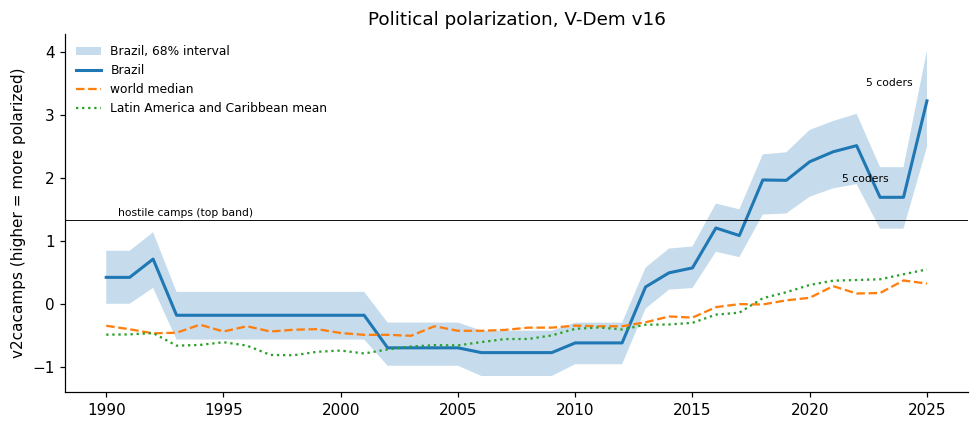

,brazil,lo68,hi68,coders,rank,of,v2smpolsoc
year,,,,,,,
2002,-0.69,-0.98,-0.29,5.0,102.0,177,0.66
2010,-0.61,-0.95,-0.29,11.0,102.0,178,0.54
2014,0.50,0.23,0.88,11.0,63.0,179,-0.49
2018,1.97,1.42,2.38,11.0,11.0,179,-1.98
2022,2.51,1.90,3.02,10.0,13.0,179,-2.73
2023,1.70,1.20,2.17,9.0,25.0,179,-1.04
2024,1.70,1.20,2.17,5.0,29.0,178,-0.73
2025,3.22,2.49,4.02,5.0,4.0,175,-0.73


In [3]:
br = pol[pol.country_name == "Brazil"].set_index("year")
world_med = pol.groupby("year")["v2cacamps"].median()
latam = pol[pol.e_regionpol_6C == 2].groupby("year")["v2cacamps"].mean()
rank = pol.dropna(subset=["v2cacamps"]).assign(r=lambda d: d.groupby("year")["v2cacamps"].rank(ascending=False))
br_rank = rank[rank.country_name == "Brazil"].set_index("year")["r"]
n_countries = rank.groupby("year").size()
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(br.index, br.v2cacamps_codelow, br.v2cacamps_codehigh, alpha=0.25, label="Brazil, 68% interval")
ax.plot(br.index, br.v2cacamps, lw=2, label="Brazil")
ax.plot(world_med.index, world_med, ls="--", label="world median")
ax.plot(latam.index, latam, ls=":", label="Latin America and Caribbean mean")
ax.axhline(1.34, c="k", lw=0.6); ax.text(1990.5, 1.4, "hostile camps (top band)", fontsize=7)
for y in (2024, 2025): ax.annotate(f"{int(br.loc[y,'v2cacamps_nr'])} coders", (y, br.loc[y,'v2cacamps']), fontsize=7, xytext=(-40, 10), textcoords="offset points")
ax.set_ylabel("v2cacamps (higher = more polarized)"); ax.set_title("Political polarization, V-Dem v16"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "vdem_brazil.png"); plt.show()
tbl = pd.DataFrame({"brazil": br.v2cacamps, "lo68": br.v2cacamps_codelow, "hi68": br.v2cacamps_codehigh,
                    "coders": br.v2cacamps_nr, "rank": br_rank, "of": n_countries,
                    "v2smpolsoc": br.v2smpolsoc}).loc[[2002, 2010, 2014, 2018, 2022, 2023, 2024, 2025]]
STATS["brazil_v2cacamps_2025"] = round(br.loc[2025, "v2cacamps"], 2)
STATS["brazil_rank_2025"] = f"{int(br_rank.loc[2025])} of {int(n_countries.loc[2025])}"
STATS["brazil_rank_2022"] = f"{int(br_rank.loc[2022])} of {int(n_countries.loc[2022])}"
tbl.round(2)

**Caveats that matter.**
- The 2024 and 2025 Brazil estimates rest on 5 coders, against 9-11 earlier. The 2025 interval overlaps the 2022 one.
- The two V-Dem measures diverge after 2022: hostility between camps (`v2cacamps`) went back up, while opinion distance (`v2smpolsoc`) eased.
- The divergence fits the survey literature. Brazilians are split more by how they feel about the other side than by what they think about issues.

## 3. Is the world becoming like this?

Two separate claims hide in that question, and the data answers them differently.

**(a) More countries are polarized into hostile camps.** Computed from V-Dem: the share of countries in the top band, unweighted and weighted by population. V-Dem's population series ends in 2019, so later years use each country's 2019 population. That is a stated approximation.

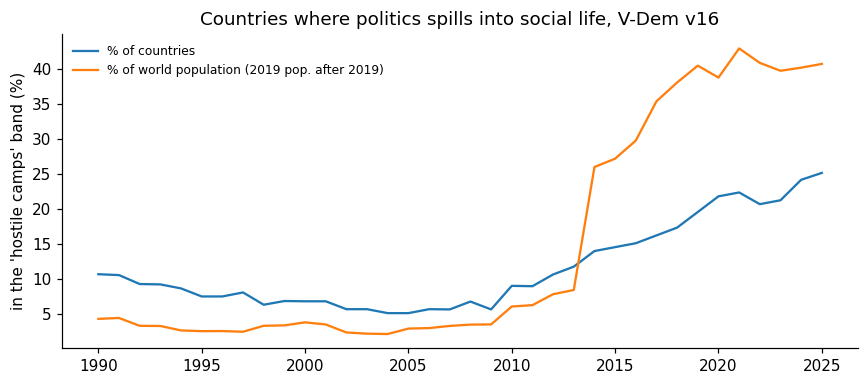

,n,share_countries,share_population
year,,,
1990,169.0,0.107,0.043
2000,177.0,0.068,0.038
2010,178.0,0.090,0.060
2015,179.0,0.145,0.272
2020,179.0,0.218,0.388
2025,175.0,0.251,0.407


In [4]:
p = pol.dropna(subset=["v2cacamps"]).copy()
p["pop"] = p.groupby("country_text_id")["e_pop"].transform(lambda s: s.ffill())
p["hostile"] = p["v2cacamps"] >= 1.34
share = p.groupby("year").apply(lambda d: pd.Series({
    "n": len(d), "share_countries": d.hostile.mean(),
    "share_population": (d.hostile * d["pop"]).sum() / d["pop"].sum()}), include_groups=False)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(share.index, 100 * share.share_countries, label="% of countries")
ax.plot(share.index, 100 * share.share_population, label="% of world population (2019 pop. after 2019)")
ax.set_ylabel("in the 'hostile camps' band (%)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("Countries where politics spills into social life, V-Dem v16")
fig.tight_layout(); fig.savefig(FIG / "vdem_world_hostile.png"); plt.show()
STATS["hostile_share_countries"] = {y: round(100 * share.loc[y, "share_countries"], 1) for y in (2000, 2010, 2020, 2025)}
STATS["hostile_share_population"] = {y: round(100 * share.loc[y, "share_population"], 1) for y in (2000, 2010, 2020, 2025)}
share.loc[[1990, 2000, 2010, 2015, 2020, 2025]].round(3)

A population-weighted line is only as broad as the countries behind it, so the next cell shows who moves it.

In [5]:
def hostile_set(y): return set(p[(p.year == y) & p.hostile].country_name)
entered_2014 = hostile_set(2014) - hostile_set(2013)
last_pop = p.groupby("country_name")["pop"].last()
top25 = sorted(hostile_set(2025), key=lambda c: -last_pop.get(c, 0))[:8]
pop_share_top = {c: round(100 * last_pop[c] / p[p.year == 2025]["pop"].sum(), 1) for c in top25}
STATS["entered_hostile_2014"] = sorted(entered_2014)
STATS["largest_hostile_2025_pop_share_pct"] = pop_share_top
print("entered the hostile band in 2014:", sorted(entered_2014))
print("largest countries in the band in 2025, % of the 2025 country-set population:", pop_share_top)

entered the hostile band in 2014: ['India', 'Malaysia', 'Malta', 'North Macedonia', 'Ukraine']
largest countries in the band in 2025, % of the 2025 country-set population: {'India': np.float64(17.8), 'United States of America': np.float64(4.4), 'Brazil': np.float64(2.8), 'Bangladesh': np.float64(2.2), 'Mexico': np.float64(1.7), 'Türkiye': np.float64(1.1), 'Thailand': np.float64(0.9), 'France': np.float64(0.9)}


**Reading.** The step in 2014 is mostly India entering the band. India alone is about a sixth of the world's population, and the US, Brazil, Bangladesh, Mexico and Turkey follow. So "40% of humanity lives in a hostile-camps country" is true under this cut-off, but it is driven by a handful of very large countries. The unweighted line, roughly one country in four in 2025 against one in fifteen in 2000, is the broader signal.

**(b) More elections are coin flips.** This is a different claim, and I couldn't find a published cross-national test of it. So here is one.

- **Data:** V-Dem records the vote shares of the top two presidential candidates (first round where there are two). That gives 378 elections held while the country was at least an electoral democracy (`v2x_regime` ≥ 2), 1990-2025.
- **Test:** is the margin shrinking over time *within* countries? It uses OLS with country fixed effects and country-clustered standard errors, plus a logit for "closer than 5 points".

In [6]:
d = pres[pres.v2x_regime >= 2].copy()
d["close5"] = (d.margin_pp < 5).astype(int)
d["decade"] = (d.year - 2000) / 10
ols = smf.ols("margin_pp ~ decade + C(country_text_id)", data=d).fit(cov_type="cluster", cov_kwds={"groups": d["country_text_id"]})
logit = smf.logit("close5 ~ decade", data=d).fit(disp=False, cov_type="cluster", cov_kwds={"groups": d["country_text_id"]})
b, ci = ols.params["decade"], ols.conf_int().loc["decade"].tolist()
bl, cil = logit.params["decade"], logit.conf_int().loc["decade"].tolist()
bins = pd.cut(d.year, [1989, 1995, 2000, 2005, 2010, 2015, 2020, 2025])
g = d.groupby(bins, observed=True)["close5"].agg(["sum", "count"])
g[["lo", "hi"]] = np.array([proportion_confint(s, n, method="wilson") for s, n in zip(g["sum"], g["count"])])
g["share"] = g["sum"] / g["count"]
STATS["closeness_test"] = {"n_elections": int(len(d)), "n_countries": int(d.country_text_id.nunique()),
    "ols_margin_change_pp_per_decade": round(b, 2), "ols_95ci": [round(x, 2) for x in ci],
    "logit_close5_log_odds_per_decade": round(bl, 3), "logit_95ci": [round(x, 3) for x in cil],
    "share_close5_overall": round(d.close5.mean(), 3)}
print(json.dumps(STATS["closeness_test"], indent=1)); g.round(3)

{
 "n_elections": 378,
 "n_countries": 73,
 "ols_margin_change_pp_per_decade": -1.04,
 "ols_95ci": [
  -2.77,
  0.68
 ],
 "logit_close5_log_odds_per_decade": 0.057,
 "logit_95ci": [
  -0.135,
  0.249
 ],
 "share_close5_overall": 0.267
}


,sum,count,lo,hi,share
year,,,,,
"(1989, 1995]",11,40,0.161,0.428,0.275
"(1995, 2000]",14,55,0.158,0.383,0.255
"(2000, 2005]",15,54,0.176,0.409,0.278
"(2005, 2010]",12,54,0.132,0.349,0.222
"(2010, 2015]",16,56,0.184,0.415,0.286
"(2015, 2020]",16,63,0.163,0.373,0.254
"(2020, 2025]",17,56,0.199,0.433,0.304


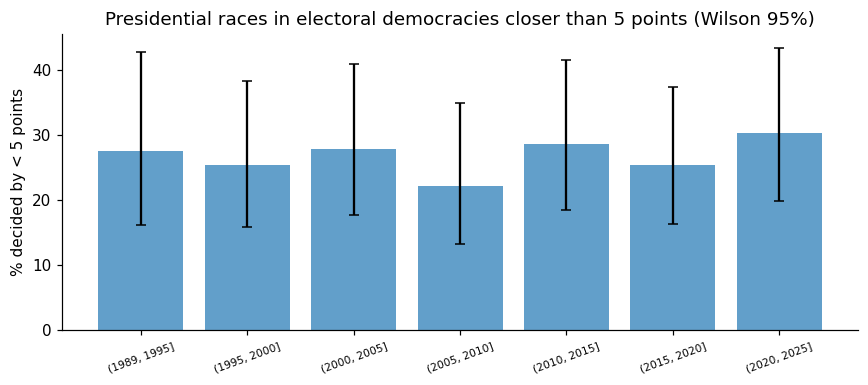

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(g)); ax.bar(x, 100 * g.share, yerr=[100 * (g.share - g.lo), 100 * (g.hi - g.share)], capsize=3, alpha=0.7)
ax.set_xticks(x, [str(i) for i in g.index], fontsize=7, rotation=20); ax.set_ylabel("% decided by < 5 points")
ax.set_title("Presidential races in electoral democracies closer than 5 points (Wilson 95%)")
fig.tight_layout(); fig.savefig(FIG / "closeness_trend.png"); plt.show()

The convenience sample of recent *final rounds* (runoffs and US generals, 17 races) is below. A selected sample cannot show a trend, and it is shown only to place today's race.

In [8]:
pres_close = close.copy()
k, n = int((pres_close.margin_pp.abs() < 5).sum()), len(pres_close)
lo, hi = proportion_confint(k, n, method="wilson")
STATS["recent_final_rounds_close5"] = {"k": k, "n": n, "wilson95": [round(lo, 2), round(hi, 2)]}
print(f"{k} of {n} recent final rounds decided by < 5 points (Wilson 95%: {lo:.0%}-{hi:.0%})")
pres_close.sort_values("margin_pp")[["country", "year", "round", "margin_pp", "confidence"]]

10 of 17 recent final rounds decided by < 5 points (Wilson 95%: 36%-78%)


,country,year,round,margin_pp,confidence
0,United States,2016,general (Electoral College winner lost popular...,-2.10,high
14,Peru,2021,runoff,0.25,medium-high
11,Colombia,2026,runoff (preliminary count 99.99%),0.96,medium
2,United States,2024,general,1.47,high
15,Poland,2025,runoff,1.78,high
5,Brazil,2022,runoff,1.80,high
8,Argentina,2015,runoff,2.68,high
10,Colombia,2022,runoff,3.13,medium
3,Brazil,2014,runoff,3.28,medium
1,United States,2020,general,4.46,high


## 4. Where the line runs: the cleavages inside the 2026 runoff

Datafolha's final crosstabs (valid votes) give the gap in Flávio's share between paired groups. Brazil has no official exit polls, so these come from pre-election polls with subgroup margins of ±3-4 points.

In [9]:
pairs = [("religion", "Evangelical", "Catholic"), ("region", "Sul", "Nordeste"), ("income", "Above 2 min wages", "Up to 2 min wages"),
         ("race", "Branco", "Preto"), ("education", "Medio/Superior", "Fundamental"), ("gender", "Men", "Women"), ("age", "35-44", "16-24")]
x = xt.set_index(["dimension", "group"])["flavio_vv"]
gaps = pd.DataFrame([{"dimension": dim, "group_a": a, "flavio_a": x[(dim, a)], "group_b": b_, "flavio_b": x[(dim, b_)],
                      "gap_pp": x[(dim, a)] - x[(dim, b_)]} for dim, a, b_ in pairs]).sort_values("gap_pp", ascending=False)
STATS["cleavage_gaps_pp"] = dict(zip(gaps.dimension, gaps.gap_pp.astype(float)))
gaps

,dimension,group_a,flavio_a,group_b,flavio_b,gap_pp
1,region,Sul,65,Nordeste,33,32
0,religion,Evangelical,70,Catholic,44,26
2,income,Above 2 min wages,58,Up to 2 min wages,42,16
3,race,Branco,55,Preto,39,16
4,education,Medio/Superior,55,Fundamental,40,15
5,gender,Men,56,Women,46,10
6,age,35-44,54,16-24,46,8


Region and religion cut deepest. A 32-point gap between the South and the Nordeste and a 26-point gap between evangelicals and Catholics are larger than the gaps by gender or age. In a race decided by 1-3 points, *which* identities line up with the vote matters more than how strongly any single voter feels.

## 5. What a 50/50 election does to people: the evidence

The table is curated and every row has a source. It is grouped into three blocks:
- what polarization does to social life;
- what elections do to individual psychology;
- the counter-evidence, which is substantial and usually left out.

In [10]:
pd.set_option("display.max_colwidth", 140)
lit[["id", "domain", "claim", "value", "n", "year", "confidence"]]

,id,domain,claim,value,n,year,confidence
0,A1.1,affective polarization (cross-national),US in-party minus out-party thermometer gap rose 27.4 to 56.3 (1978-2020); largest rise of 12 OECD countries; six countries fell,+5.6 pts/decade,12 countries,2024,high
1,A1.6,affective polarization (cross-national),"Partisan API rose significantly only in US, Denmark, New Zealand, Canada; most countries show no significant trend",US +0.050/survey-year (0-10),"191 election studies, 18 democracies",2023,high
2,B1.1,Brazil affective polarization,"Share maximally polarized toward the two runoff leaders (score 10 on 0-10 difference) in 2018; polarization predominantly affective, not...",24.3%,ESEB 2002-2018,2023,high
3,B1.3,Brazil affective polarization,"Trust in the other camp on 0-10: bolsonaristas trust petistas 0.8, petistas trust bolsonaristas 1.0; own camp 7.8 and 7.3",0.8 / 1.0,"2,004",2025,medium
4,B3.1,Brazil social life,"Stopped talking politics with friends or family to avoid fights (54% of Lula voters, 40% of Bolsonaro voters); 19% of social-media users...",49%,"2,566",2022,high
5,B3.5,Brazil social life,Fear of physical aggression over one's political choice,67.5% (2022) to 59.6% (2026),"2,100 (2022)",2022/2026,medium
6,B3.6,Brazil social life,Adults who see strong or very strong conflict between supporters of different parties (19-country 2022 median: 65%),80%,"1,054",2024,high
7,B6.2,Brazil trust in elections,"Trust in electronic voting machines: overall 53%, Bolsonaro supporters 18%, Lula supporters 78%",53% / 18% / 78%,"2,004",2026,medium-high
8,C1,psychology: stress,US adults calling the presidential election a significant stress source,"52% (2016), 68% (2020), 69% (2024)",">3,000 per wave",2016-2024,high
9,C1b,psychology: stress,"US adults calling societal division a significant stressor; of those, 61% feel isolated vs 43% of the rest (cross-sectional)",62%,"3,199",2025,high


In [11]:
# Two small computations on the cited figures
camp = pd.DataFrame({"camp": ["petistas", "bolsonaristas"], "perceived_pct": [26, 25], "self_identified_pct": [16, 13]})
camp["overestimate_x"] = (camp.perceived_pct / camp.self_identified_pct).round(2)
STATS["camp_size_overestimate_x"] = dict(zip(camp.camp, camp.overestimate_x))
swd = pd.DataFrame({"year": [2019, 2024], "government": ["Bolsonaro", "Lula"], "winner_minus_loser_pp": [18, 25]})
display(camp); display(swd)

,camp,perceived_pct,self_identified_pct,overestimate_x
0,petistas,26,16,1.62
1,bolsonaristas,25,13,1.92


,year,government,winner_minus_loser_pp
0,2019,Bolsonaro,18
1,2024,Lula,25


**What the evidence supports, and what it doesn't.**

1. **Losing hurts, briefly and then structurally.** The acute drop in happiness after a loss fades within about a week (US panel, regression discontinuity). Satisfaction with democracy is different: the loss persists for years (Danish panel). In Brazil it **swaps sides with the government**, from +18 points for the winning camp under Bolsonaro to +25 under Lula (Pew). Whoever loses tonight inherits the low-satisfaction half of that table.
2. **The social cost is measurable and large.**
   - Half of voters stopped talking politics with friends or family in 2022 (Datafolha, n = 2,566).
   - Trust across the line sits near 1 out of 10 (Quaest, n = 2,004).
   - 80% see strong conflict between party supporters (Pew), above the 19-country median of 65%.
3. **Physiology is suggestive, not established.** The cortisol and testosterone studies are small, single-site and not pre-registered. I cite them as mechanisms worth testing, not as effect sizes.
4. **The perception gap is the most robust finding of all, and the most hopeful.**
   - People overestimate the other side's hostility and support for violence by 2× to 4× (US; replicated in 26 countries).
   - Brazilians picture the hard camps as 1.6-1.9× their actual size.
   - Interventions that correct this reduce animosity. In a 32,059-person megastudy, 23 of 25 worked, but only about a third of the effect survived two weeks.
5. **The data does not show** that coin-flip elections are a new global norm (Section 3b). It *does* show more countries sliding into hostile camps (Section 3a). Those are different claims, and they are easy to confuse.

## 6. Summary numbers

Every number the essay quotes is here, generated by the cells above.

In [12]:
out = ROOT / "results" / "part_b_stats.json"
out.write_text(json.dumps(STATS, indent=2, default=float)); print(json.dumps(STATS, indent=1, default=float))

{
 "outcome_entropy_bits": 0.621,
 "electorate_entropy_bits_at_median": 0.99927,
 "losing_side_millions_median": 57.6,
 "losing_side_millions_80": [
  55.2,
  59.2
 ],
 "p_margin_below_2m_votes": 0.236,
 "p_margin_below_1m_votes": 0.117,
 "brazil_v2cacamps_2025": 3.22,
 "brazil_rank_2025": "4 of 175",
 "brazil_rank_2022": "13 of 179",
 "hostile_share_countries": {
  "2000": 6.8,
  "2010": 9.0,
  "2020": 21.8,
  "2025": 25.1
 },
 "hostile_share_population": {
  "2000": 3.8,
  "2010": 6.0,
  "2020": 38.8,
  "2025": 40.7
 },
 "entered_hostile_2014": [
  "India",
  "Malaysia",
  "Malta",
  "North Macedonia",
  "Ukraine"
 ],
 "largest_hostile_2025_pop_share_pct": {
  "India": 17.8,
  "United States of America": 4.4,
  "Brazil": 2.8,
  "Bangladesh": 2.2,
  "Mexico": 1.7,
  "T\u00fcrkiye": 1.1,
  "Thailand": 0.9,
  "France": 0.9
 },
 "closeness_test": {
  "n_elections": 378,
  "n_countries": 73,
  "ols_margin_change_pp_per_decade": -1.04,
  "ols_95ci": [
   -2.77,
   0.68
  ],
  "logit_close5

## Limitations

- **V-Dem is expert-coded.** It is good for comparing countries, but it can echo media narratives. Brazil's 2024-2025 values rest on 5 coders.
- **The closeness test uses first-round shares** where there are two rounds. Runoffs are closer by construction, and they are not in V-Dem's vote-share variables.
- **Crosstab gaps are pre-election subgroup estimates,** not exit polls.
- **Most of the psychology evidence is from the US.** Brazil-specific clinical evidence on winners and losers was not found.
- **The essay framing is mine.** The numbers are not.